HOMEWORK 15

In this homework we will be working with the Fashion MNIST dataset. You will be given a classifier which suffers from considerable overfitting. Your objective will be to employ regularization techniques to mitigate the overfitting problem.

Let's start with the usual imports.

In [6]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import numpy as np
import keras
from keras import Model
from keras.layers import Activation, BatchNormalization, Conv2D, Dense, Dropout, Flatten, Input, MaxPooling2D
from sklearn.model_selection import train_test_split

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(1234)

ValueError: The proto value '6' is already registered.

Dataset

The Fashion MNIST dataset link was built by Zalando Research and consists of monochrome images of different types of clothing, namely:

    0 T-shirt/top
    1 Trouser
    2 Pullover
    3 Dress
    4 Coat
    5 Sandal
    6 Shirt
    7 Sneaker
    8 Bag
    9 Ankle boot

It is also one of the Keras built-in datasets. Let's load the images and quickly inspect it. We keep the 10,000 test images aside for the final evaluation and hold out 6,000 of the training images as the validation set, which is used to monitor the training and to take decisions.

In [ ]:


(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
num_classes = len(class_names)

# Normalization
x_train = x_train.astype('float32')/255
x_test = x_test.astype('float32')/255

# Hold out a (class-balanced) validation set
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=6000, stratify=y_train, random_state=0)

print('Train set:      ', len(y_train), 'samples')
print('Validation set: ', len(y_val), 'samples')
print('Test set:       ', len(y_test), 'samples')
print('Sample dims:    ', x_train.shape)



29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train set:       54000 samples
Validation set:  6000 samples
Test set:        10000 samples
Sample dims:     (54000, 28, 28)


Let's visualise some random samples.

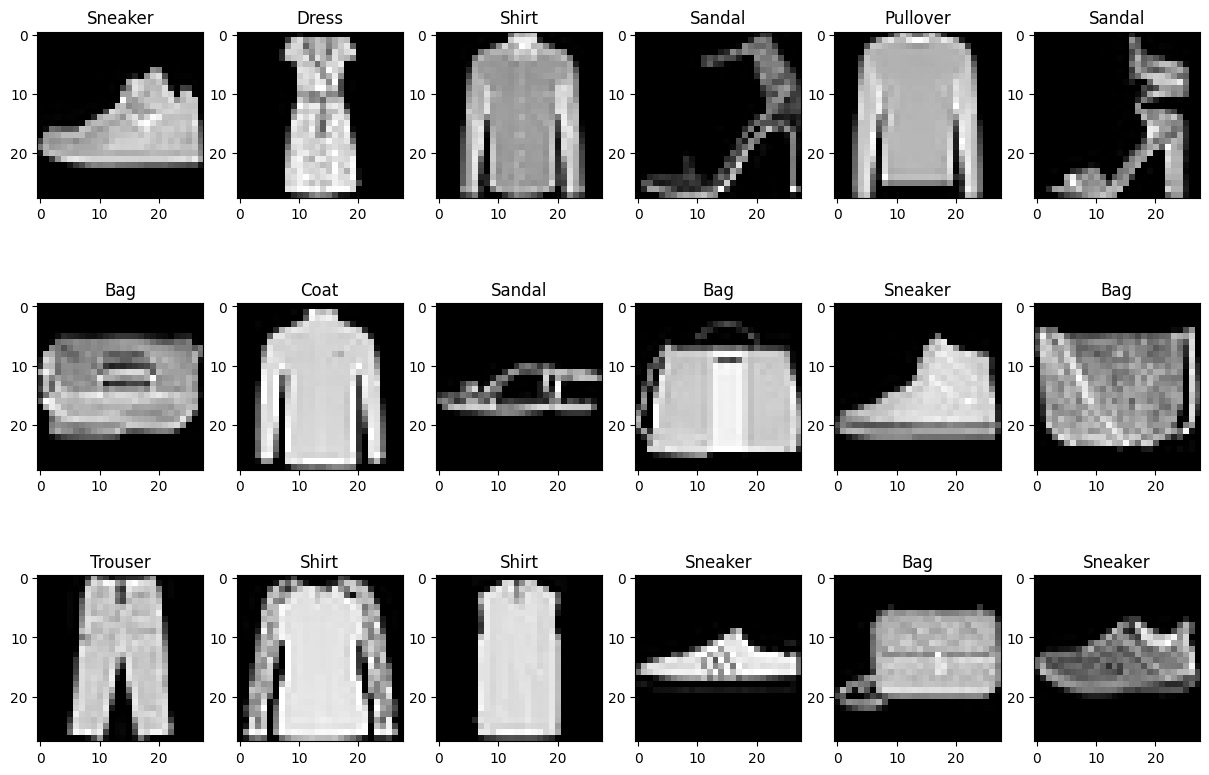

In [ ]:
cnt = 1
for r in range(3):
    for c in range(6):
        idx = np.random.randint(len(x_train))
        plt.subplot(3, 6, cnt)
        plt.imshow(x_train[idx, ...], cmap='gray')
        plt.title(class_names[y_train[idx]])
        cnt = cnt + 1



Building the Classifier

We are now going to build the baseline classifier that you will use throughout this homework.

In [ ]:
inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same')(inputs)
net = Flatten()(net)
net = Dense(128, activation="relu")(net)
outputs = Dense(10, activation="softmax")(net)

model = Model(inputs, outputs)
model.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,213,002 (12.26 MB)

 Trainable params: 3,213,002 (12.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
epochs = 50
batch_size = 64

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_data=(x_val, y_val), verbose=2)

Epoch 1/50
844/844 - 17s - 20ms/step - accuracy: 0.8843 - loss: 0.3054 - val_accuracy: 0.9210 - val_loss: 0.2396
Epoch 2/50
844/844 - 19s - 22ms/step - accuracy: 0.8887 - loss: 0.2855 - val_accuracy: 0.9177 - val_loss: 0.2521
Epoch 3/50
844/844 - 16s - 19ms/step - accuracy: 0.8928 - loss: 0.2769 - val_accuracy: 0.9172 - val_loss: 0.2485
Epoch 4/50
844/844 - 17s - 20ms/step - accuracy: 0.8949 - loss: 0.2749 - val_accuracy: 0.9177 - val_loss: 0.2387
Epoch 5/50
844/844 - 16s - 19ms/step - accuracy: 0.8957 - loss: 0.2700 - val_accuracy: 0.9177 - val_loss: 0.2475
Epoch 6/50
844/844 - 16s - 19ms/step - accuracy: 0.8963 - loss: 0.2669 - val_accuracy: 0.9198 - val_loss: 0.2423
Epoch 7/50
844/844 - 16s - 20ms/step - accuracy: 0.8983 - loss: 0.2615 - val_accuracy: 0.9192 - val_loss: 0.2504
Epoch 8/50
844/844 - 16s - 19ms/step - accuracy: 0.9006 - loss: 0.2540 - val_accuracy: 0.9167 - val_loss: 0.2468
Epoch 9/50
844/844 - 16s - 19ms/step - accuracy: 0.9002 - loss: 0.2555 - val_accuracy: 0.9180 - 

KeyboardInterrupt: 

Train Acc      0.9983518719673157
Validation Acc 0.9071666598320007


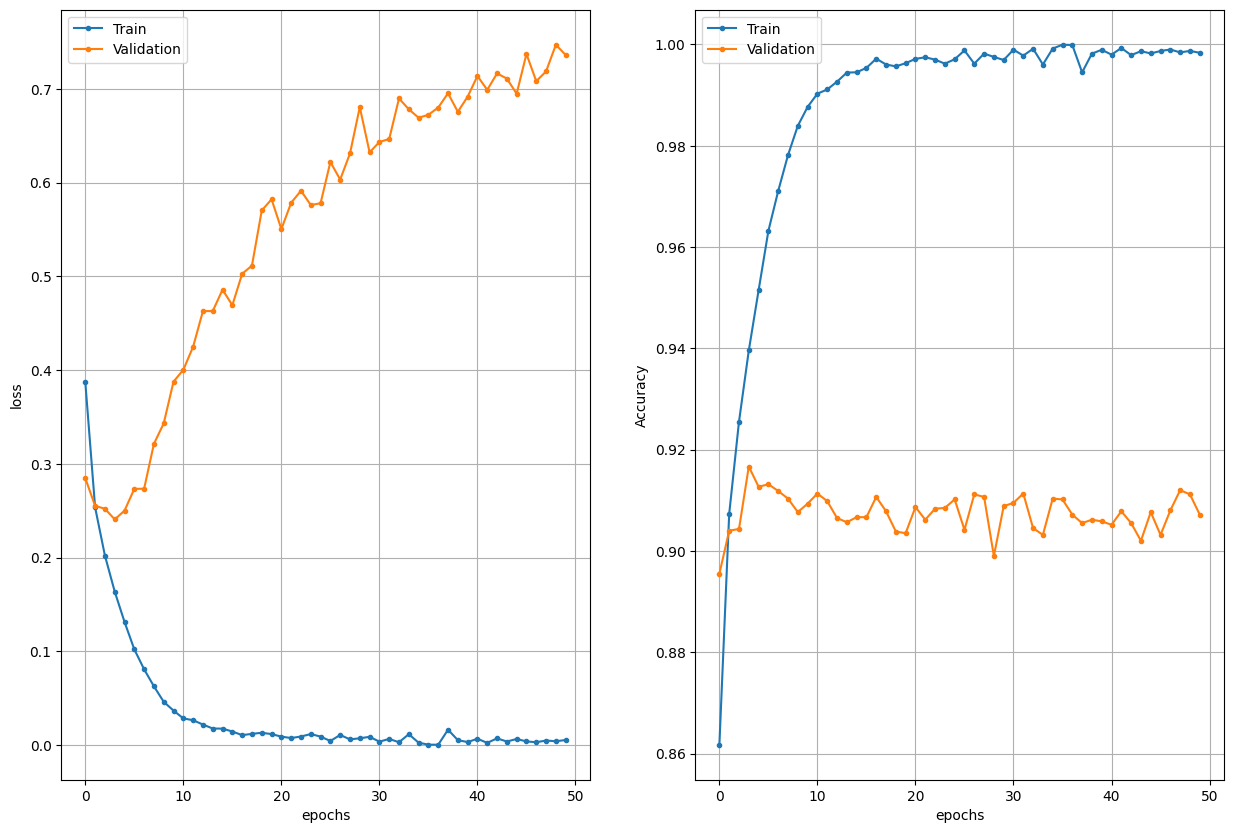

In [ ]:

def plot_history(history):
    h = history.history
    epochs = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                               epochs, h['val_accuracy'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'])

    print('Train Acc     ', h['accuracy'][-1])
    print('Validation Acc', h['val_accuracy'][-1])

plot_history(history)



As you can see, the classifier suffers from massive overfitting. The training accuracy is close to 1 (0.998), while the validation accuracy is only about 90%. The validation loss reaches its minimum after just a few epochs (the validation accuracy peaks at about 91.5% in epoch 6) and then it keeps growing steadily, which is the typical sign of overfitting.
Combat the Overfitting!

Now it is your turn. Use the classifier as a baseline, include some regularization techniques and try to improve the classification performance. You can try any techniques you might see fit, e.g.,

    Dropout
    Batch normalization
    Weight regularization
    Data augmentation
    Early stopping
    Pooling
    Reducing the number of parameters (the size of the network)
    ...

There are two objectives you shall fulfill in order to successfully complete this homework:

    The validation accuracy shall be above 91%
    Your network (with all the regularizations applied) shall not be larger than the baseline

Use the validation set for all your decisions. The test set is meant only for the final evaluation of your best network.

Note: fit continues training the model it is called on. Whenever you start a new experiment (even if you change only the training, e.g. the augmentation), run the cell that builds the model again to get a freshly initialized one.


In [ ]:
# Modify the baseline classifier in order to reduce the overfitting and make the performance more robust
inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, kernel_size=(3, 3), padding='same')(inputs)
net = BatchNormalization()(net)
net = Activation('relu')(net)
net = MaxPooling2D(pool_size=(2,2))(net)
net = Conv2D(32, kernel_size=(3, 3), padding='same')(net)
net = BatchNormalization()(net)
net = Activation('relu')(net)
net = MaxPooling2D(pool_size=(2,2))(net)
net = Flatten()(net)
net = Dense(128, activation="relu")(net)
net = Dropout(0.7)(net)
outputs = Dense(10, activation="softmax")(net)

model = Model(inputs, outputs)
model.summary()

NameError: name 'Input' is not defined

In [ ]:
import cv2
#data augmentation

def datagen(x, y, batch_size):
    num_samples = len(y)
    while True:
        indices = np.random.permutation(num_samples)
        for start in range(0, num_samples - batch_size + 1, batch_size):
            idx = indices[start:start + batch_size]
            x_batch, y_batch = x[idx], y[idx]            # indexing with an array makes a copy, x is not modified

            # Augmentation: mirror a random half of the batch
            flip = np.random.rand(batch_size) > 0.5
            #x_batch[flip] = x_batch[flip, :, ::-1]
            for i in np.where(blur):
              x_batch[i] = cv2.GaussianBlur(x_batch[i], ksize=(3,3), sigmaX=3)

            yield x_batch, y_batch


steps_per_epoch = len(y_train) // batch_size
generator = datagen(x_train, y_train, batch_size)

checkpoint = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history_flip = model.fit(generator, steps_per_epoch=steps_per_epoch, epochs=epochs, validation_data=(x_val, y_val), callbacks=[checkpoint], shuffle=False, verbose=2)

Epoch 1/50
843/843 - 19s - 22ms/step - accuracy: 0.4261 - loss: 1.5827 - val_accuracy: 0.8070 - val_loss: 0.5053
Epoch 2/50
843/843 - 18s - 22ms/step - accuracy: 0.4866 - loss: 1.4190 - val_accuracy: 0.8398 - val_loss: 0.4498
Epoch 3/50
843/843 - 18s - 22ms/step - accuracy: 0.5079 - loss: 1.3630 - val_accuracy: 0.8520 - val_loss: 0.4040
Epoch 4/50
843/843 - 19s - 22ms/step - accuracy: 0.5170 - loss: 1.3348 - val_accuracy: 0.8625 - val_loss: 0.3785
Epoch 5/50
843/843 - 18s - 22ms/step - accuracy: 0.5311 - loss: 1.3002 - val_accuracy: 0.8695 - val_loss: 0.3543
Epoch 6/50
843/843 - 18s - 22ms/step - accuracy: 0.5413 - loss: 1.2768 - val_accuracy: 0.8707 - val_loss: 0.3477
Epoch 7/50
843/843 - 18s - 22ms/step - accuracy: 0.5495 - loss: 1.2531 - val_accuracy: 0.8897 - val_loss: 0.3104
Epoch 8/50
843/843 - 19s - 23ms/step - accuracy: 0.5564 - loss: 1.2330 - val_accuracy: 0.8930 - val_loss: 0.2978
Epoch 9/50
843/843 - 19s - 22ms/step - accuracy: 0.5636 - loss: 1.2110 - val_accuracy: 0.8918 - 

KeyboardInterrupt: 

Train Acc      0.4967007637023926
Validation Acc 0.9086666703224182


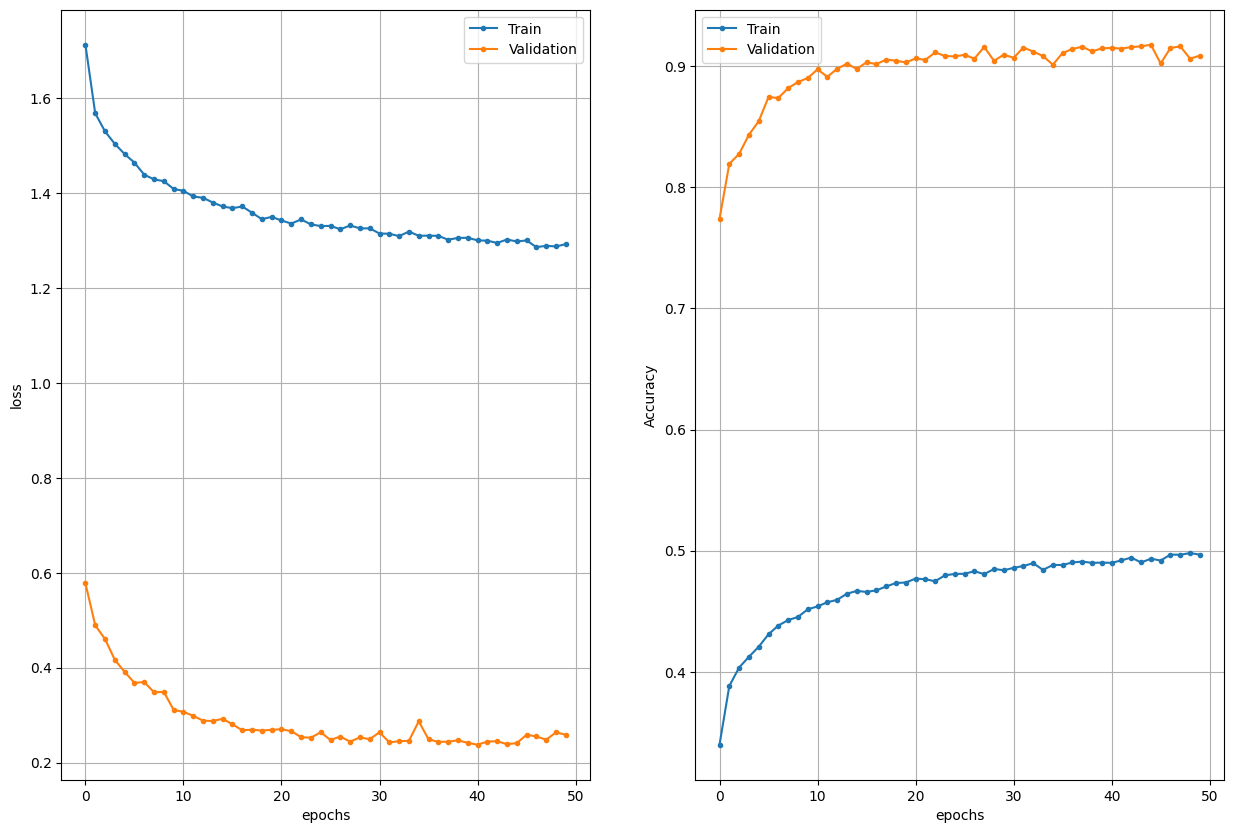

In [ ]:
plot_history(history_flip)